# Light output comparison: OpenMC vs MCNPX-PoliMi

Compares the light output histograms saved by `2_run_pyMPPost.ipynb` (OpenMC) and `2_run_pyMPPost_MCNP.ipynb`
(MCNPX-PoliMi) for every case listed in the configuration cell, grouped by source particle (neutrons, photons).
For each case the notebook shows both histograms, the pull per bin and a summary of the agreement
(χ²/ndf, mean and standard deviation of the pull, fraction of bins within 1σ and 2σ).

pyMPPost can be downloaded from: https://gitlab.eecs.umich.edu/umich-dnng/pymppost

In [1]:
import os

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

In [2]:
# ================================ CONFIGURATION ================================
RESULTS_DIR = "/Users/loren/WORKSPACE/PHOTON/verification-and-validation/3-coupling-OpenMC-MPPost/results"

# Cases to compare: sub-folder of RESULTS_DIR, source particle, panel label,
# optional x-axis limit [MeVee] (None = automatic)
CASES = [
    # --- neutrons
    {"folder": "trans-stilbene/252Cf", "particle": "neutron", "label": r"$^{252}$Cf – trans-stilbene", "xlim": None, "ylim": (2e-6, 2e-1)},
    {"folder": "trans-stilbene/DD",    "particle": "neutron", "label": r"DD – trans-stilbene",           "xlim": None, "ylim": (2e-4, 1.7e-2)},
    {"folder": "helium4/252Cf",        "particle": "neutron", "label": r"$^{252}$Cf – $^{4}$He",          "xlim": None, "ylim": (6e-6, 5e-2)},
    {"folder": "helium4/DD",           "particle": "neutron", "label": r"DD – $^{4}$He",                 "xlim": None, "ylim": (6e-5, 1.6e-2)},
    # --- photons
    {"folder": "sodium-iodide/137Cs",  "particle": "photon",  "label": r"$^{137}$Cs – NaI(Tl)",          "xlim": None, "ylim": (2e-5, 5e-1)},
    {"folder": "sodium-iodide/152Eu",  "particle": "photon",  "label": r"$^{152}$Eu – NaI(Tl)",          "xlim": None, "ylim": (5e-6, 5e-1)},
]

# Saved histograms: file name pattern ({particle} is filled per case) and key prefix
CODES = {
    "OpenMC":       {"file": "OpenMC_LO_histogram_{particle}.joblib",       "label": "OpenMC"},
    "MCNPX-PoliMi": {"file": "MCNPX-PoliMi_LO_histogram_{particle}.joblib", "label": "MCNPX-PoliMi"},
}
REFERENCE = "MCNPX-PoliMi"            # pull = (test - reference) / sigma

# Symbol of the source particle in the y-axis label
PAR_SYMBOL = {"neutron": "n", "photon": r"$\mathrm{\gamma}$"}

# Pull and statistics
PULL_LIM   = 3.0                      # y-range of the pull panel; points outside are drawn as arrows
MIN_COUNTS = 10                       # bins with fewer total raw counts are excluded from pull and χ²
LOW_COUNTS = 100                      # bins with fewer total raw counts get hollow pull markers

# Plot style
PLOT_STYLE = "points"                 # "points" (test code as markers) or "lines"

# Figures
SAVE_FIG = True
FIG_DIR  = "/Users/loren/WORKSPACE/PHOTON/verification-and-validation/3-coupling-OpenMC-MPPost/images"
FIG_FMT  = "pdf"
# ===============================================================================

TEST_CODE = next(name for name in CODES if name != REFERENCE)
PARTICLES = list(dict.fromkeys(case["particle"] for case in CASES))   # in order of appearance

# Functions

In [3]:
def load_histogram(path, label):
    """Load a saved light output histogram and recover the raw counts per bin."""
    data = joblib.load(path)
    y   = np.asarray(data[f"{label}-counts-norm"], dtype=float)
    err = np.asarray(data[f"{label}-counts-err-norm"], dtype=float)
    # Poisson errors: err / y = 1 / sqrt(N)  ->  N = (y / err)^2 (N = 0 where err = 0)
    counts = np.divide(y, err, out=np.zeros_like(y), where=err > 0) ** 2
    return {"edges": np.asarray(data[f"{label}-bin-edges"], dtype=float),
            "y": y, "err": err, "counts": np.rint(counts),
            "metadata": data.get(f"{label}-metadata", {})}


def compute_pull(test, ref):
    """Pull per bin and agreement statistics over the bins with enough counts."""
    sigma = np.hypot(test["err"], ref["err"])
    valid = (sigma > 0) & (test["counts"] + ref["counts"] >= MIN_COUNTS)
    pull = np.full_like(sigma, np.nan)
    pull[valid] = (test["y"][valid] - ref["y"][valid]) / sigma[valid]

    p = pull[valid]
    ndf = p.size
    stats = {"bins used": ndf,
             "chi2/ndf": np.sum(p**2) / ndf if ndf else np.nan,
             "mean pull": p.mean() if ndf else np.nan,
             "std pull": p.std(ddof=1) if ndf > 1 else np.nan,
             "within 1σ [%]": 100 * np.mean(np.abs(p) <= 1) if ndf else np.nan,   # expected ≈ 68 %
             "within 2σ [%]": 100 * np.mean(np.abs(p) <= 2) if ndf else np.nan}   # expected ≈ 95 %
    return pull, stats


def check_compatible(test, ref, case):
    """Stop if the two histograms cannot be compared bin by bin."""
    if test["edges"].shape != ref["edges"].shape or not np.allclose(test["edges"], ref["edges"]):
        raise ValueError(f"[{case}] different bin edges: rerun the pyMPPost notebooks with the same N_BINS / LO_MAX.")
    pbw = {m.get("per_bin_width") for m in (test["metadata"], ref["metadata"]) if m}
    if len(pbw) > 1:
        raise ValueError(f"[{case}] one histogram is per bin, the other per MeVee (PER_BIN_WIDTH).")


def plot_comparison(test, ref, pull, stats, case, par, yscale="log",
                    style="points", panel_label=None, ylim=None,
                    low_counts=100, figsize=(8, 8)):
    """
    Histograms (top) and pull (bottom) for one case.

    style       : "points" -> test code as markers with error bars over the reference band
                  "lines"  -> both codes as step lines (reference with its ±1σ band)
    panel_label : e.g. r"(a) $^{137}$Cs – NaI(Tl)", written above the top panel (left);
                  None -> case["title"] is used instead
    ylim        : (bottom, top) of the top panel, None entries = automatic
    low_counts  : bins with fewer total raw counts get hollow pull markers
    """
    edges = ref["edges"]
    centers = 0.5 * (edges[:-1] + edges[1:])
    c_ref, c_test = "tab:blue", "tab:orange"

    fig, (ax, ax_pull) = plt.subplots(nrows=2, figsize=figsize, sharex=True,
                                      gridspec_kw={"height_ratios": [2.5, 1], "hspace": 0.05})

    # ---------- Top panel ----------
    # Reference code: step line with shaded ±1σ band
    ax.stairs(ref["y"] + ref["err"], edges, baseline=np.clip(ref["y"] - ref["err"], 0, None),
              fill=True, color=c_ref, alpha=0.25, linewidth=0, zorder=1)
    ax.stairs(ref["y"], edges, color=c_ref, linewidth=1.4, zorder=2)

    # Test code: markers (or step line) with error bars
    m = test["counts"] > 0                       # empty bins cannot be drawn on a log scale
    if style == "points":
        ax.errorbar(centers[m], test["y"][m], yerr=test["err"][m], fmt="o", ms=3.5,
                    color=c_test, elinewidth=0.9, capsize=0, zorder=3)
        test_handle = Line2D([], [], color=c_test, marker="o", ms=5, ls="none")
    else:
        ax.stairs(test["y"], edges, color=c_test, linewidth=1.4, zorder=3)
        ax.errorbar(centers[m], test["y"][m], yerr=test["err"][m], fmt="none",
                    ecolor=c_test, elinewidth=0.8, capsize=0, zorder=3)
        test_handle = Line2D([], [], color=c_test, lw=1.4)

    # Legend entries drawn as they appear in the plot (line + band for the reference)
    ref_handle = (Patch(color=c_ref, alpha=0.25, linewidth=0), Line2D([], [], color=c_ref, lw=1.4))
    ax.legend([test_handle, ref_handle], [TEST_CODE, REFERENCE],
              fontsize=14, frameon=False, loc="best")

    per_mevee = (ref["metadata"] or {}).get("per_bin_width", False)
    unit = r"MeVee$^{-1}$" if per_mevee else r"bin$^{-1}$"
    ax.set_ylabel(fr"Counts ({par}$^{{-1}}$ {unit})", fontsize=14)
    ax.set_yscale(yscale)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(True, which="major", linestyle=":", alpha=0.4)
    ax.tick_params(labelsize=12)

    # Panel label (or case title) on the left and agreement summary on the right,
    # both above the axes so they never overlap the data
    ax.set_title(panel_label if panel_label is not None else case["title"],
                 loc="left", fontsize=14)
    ax.set_title(fr"$\chi^2$/ndf = {stats['chi2/ndf']:.2f}", loc="right", fontsize=13)

    # ---------- Bottom panel (pull) ----------
    big = max(PULL_LIM, 5.0)
    for lo, hi, color in [(-1, 1, "green"), (1, 2, "orange"), (-2, -1, "orange"),
                          (2, big, "red"), (-big, -2, "red")]:
        ax_pull.axhspan(lo, hi, color=color, alpha=0.15, zorder=0)
    ax_pull.axhline(0, color="0.3", linewidth=1.0, zorder=1)

    low = (test["counts"] + ref["counts"]) < low_counts       # little statistical weight
    inside = np.abs(pull) <= PULL_LIM
    # Filled X: enough statistics; hollow X: few counts in the bin
    ax_pull.plot(centers[inside & ~low], pull[inside & ~low], "X", ms=5,
                 mfc="black", mec="black", mew=0.3, zorder=2)
    ax_pull.plot(centers[inside & low], pull[inside & low], "X", ms=5,
                 mfc="none", mec="black", mew=0.7, zorder=2)

    # Pulls beyond the axis limits are drawn at the edge as arrows instead of disappearing
    edge = 0.92 * PULL_LIM
    ax_pull.plot(centers[pull > PULL_LIM], np.full((pull > PULL_LIM).sum(), edge),
                 "^", color=c_test, ms=6, zorder=2)
    ax_pull.plot(centers[pull < -PULL_LIM], np.full((pull < -PULL_LIM).sum(), -edge),
                 "v", color=c_test, ms=6, zorder=2)

    ax_pull.set_xlabel("Light output (MeVee)", fontsize=14)
    ax_pull.set_ylabel(r"Pull ($\sigma$)", fontsize=14)
    ax_pull.set_ylim(-PULL_LIM, PULL_LIM)
    ax_pull.set_yticks(np.arange(-int(PULL_LIM), int(PULL_LIM) + 1))
    ax_pull.tick_params(labelsize=12)
    if case.get("xlim") is not None:
        ax_pull.set_xlim(0, case["xlim"])

    fig.align_ylabels([ax, ax_pull])
    return fig


def plot_comparison_ratio(test, ref, case, par, yscale="log",
                          style="points", panel_label=None, ylim=None,
                          ratio_lim=None, figsize=(8, 8)):
    """
    Histograms (top) and ratio test/reference with propagated error (bottom).

    style       : "points" -> test code as markers with error bars over the reference band
                  "lines"  -> both codes as step lines (reference with its ±1σ band)
    panel_label : e.g. r"(a) $^{137}$Cs – NaI(Tl)", written above the top panel (left);
                  None -> case["title"] is used instead
    ylim        : (bottom, top) of the top panel, None entries = automatic
    ratio_lim   : (bottom, top) of the ratio panel; None = automatic, wide enough to
                  show every ratio with its error bar
    """
    edges = ref["edges"]
    centers = 0.5 * (edges[:-1] + edges[1:])
    c_ref, c_test = "blue", "red"

    fig, (ax, ax_rat) = plt.subplots(nrows=2, figsize=figsize, sharex=True,
                                     gridspec_kw={"height_ratios": [2.5, 1], "hspace": 0.05})

    # ---------- Top panel ----------
    # Reference code: step line with shaded ±1σ band
    ax.stairs(ref["y"] + ref["err"], edges, baseline=np.clip(ref["y"] - ref["err"], 0, None),
              fill=True, color=c_ref, alpha=0.25, linewidth=0, zorder=1)
    ax.stairs(ref["y"], edges, color=c_ref, linewidth=1.4, zorder=2)

    # Test code: markers (or step line) with error bars
    m = test["counts"] > 0                       # empty bins cannot be drawn on a log scale
    if style == "points":
        ax.errorbar(centers[m], test["y"][m], yerr=test["err"][m], fmt="o", ms=3.5,
                    color=c_test, elinewidth=0.9, capsize=0, zorder=3)
        test_handle = Line2D([], [], color=c_test, marker="o", ms=5, ls="none")
    else:
        ax.stairs(test["y"], edges, color=c_test, linewidth=1.4, zorder=3)
        ax.errorbar(centers[m], test["y"][m], yerr=test["err"][m], fmt="none",
                    ecolor=c_test, elinewidth=0.8, capsize=0, zorder=3)
        test_handle = Line2D([], [], color=c_test, lw=1.4)

    # Legend entries drawn as they appear in the plot (line + band for the reference)
    ref_handle = (Patch(color=c_ref, alpha=0.25, linewidth=0), Line2D([], [], color=c_ref, lw=1.4))
    ax.legend([test_handle, ref_handle], [TEST_CODE, REFERENCE],
              fontsize=16, frameon=False, loc="best")

    per_mevee = (ref["metadata"] or {}).get("per_bin_width", False)
    unit = r"MeVee$^{-1}$" if per_mevee else r"bin$^{-1}$"
    ax.set_ylabel(fr"Counts ({par}$^{{-1}}$ {unit})", fontsize=18)
    ax.set_yscale(yscale)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(True, which="major", linestyle=":", alpha=0.4)
    ax.tick_params(labelsize=16)

    # Panel label (or case title) above the axes, on the left
    ax.set_title(panel_label if panel_label is not None else case["title"],
                 loc="left", fontsize=20)

    # ---------- Bottom panel (ratio) ----------
    # R = test / ref,  sigma_R = R * sqrt((sigma_test/test)^2 + (sigma_ref/ref)^2)
    valid = (test["y"] > 0) & (ref["y"] > 0)     # ratio undefined where a code has no counts
    ratio = test["y"][valid] / ref["y"][valid]
    ratio_err = ratio * np.hypot(test["err"][valid] / test["y"][valid],
                                 ref["err"][valid] / ref["y"][valid])

    ax_rat.axhline(1, color="0.3", linewidth=1.0, linestyle="--", zorder=1)
    ax_rat.errorbar(centers[valid], ratio, yerr=ratio_err, fmt="s", ms=4,
                    color="black", ecolor="black", elinewidth=0.8, capsize=2, zorder=2, label=f"{TEST_CODE} / {REFERENCE}")

    # Automatic range: every ratio and its error bar is visible, with a small margin
    if ratio_lim is None and ratio.size:
        lo, hi = np.min(ratio - ratio_err), np.max(ratio + ratio_err)
        pad = 0.05 * (hi - lo)
        ratio_lim = (lo - pad, hi + pad)
    if ratio_lim is not None:
        ax_rat.set_ylim(*ratio_lim)

    ax_rat.set_xlabel("Light output (MeVee)", fontsize=18)
    ax_rat.legend(fontsize=16, frameon = True)
    ax_rat.set_ylabel(f"Ratio (-)", fontsize=18)
    ax_rat.grid(True, which="major", linestyle=":", alpha=0.4)
    ax_rat.tick_params(labelsize=16)
    if case.get("xlim") is not None:
        ax_rat.set_xlim(0, case["xlim"])

    fig.align_ylabels([ax, ax_rat])
    return fig

# Comparison

One loop over all the cases, grouped by source particle. Panel letters restart for each particle,
so that neutron and photon figures can be used as separate figure sets.


==================== NEUTRON ====================


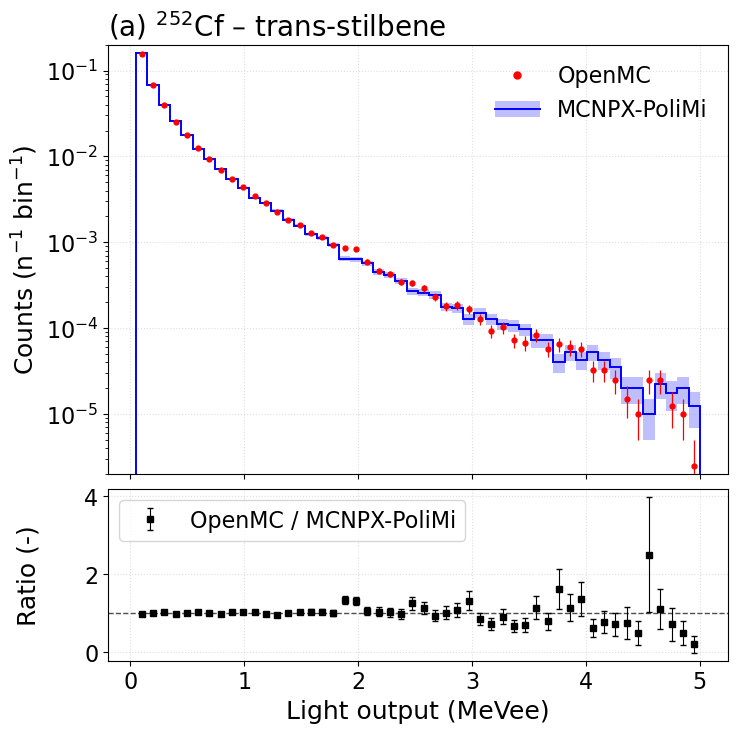

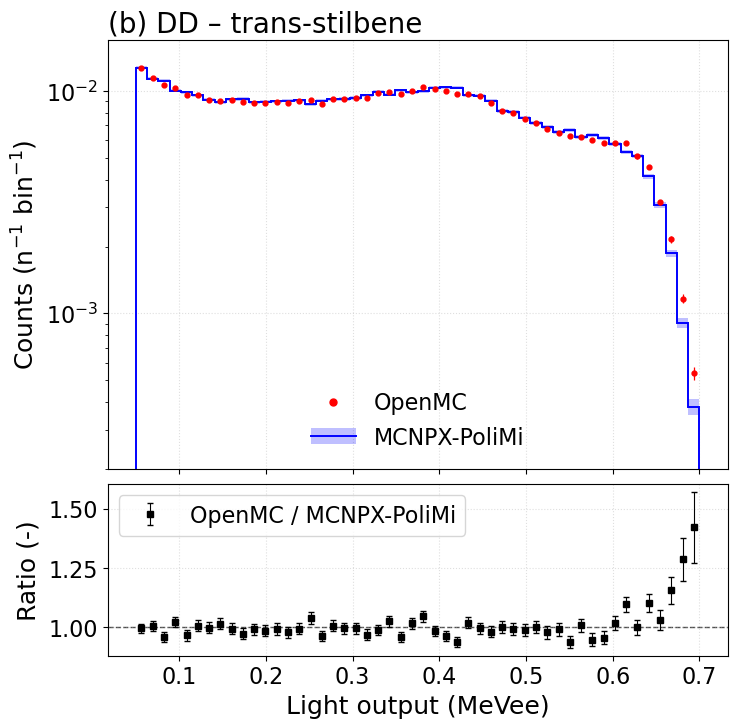

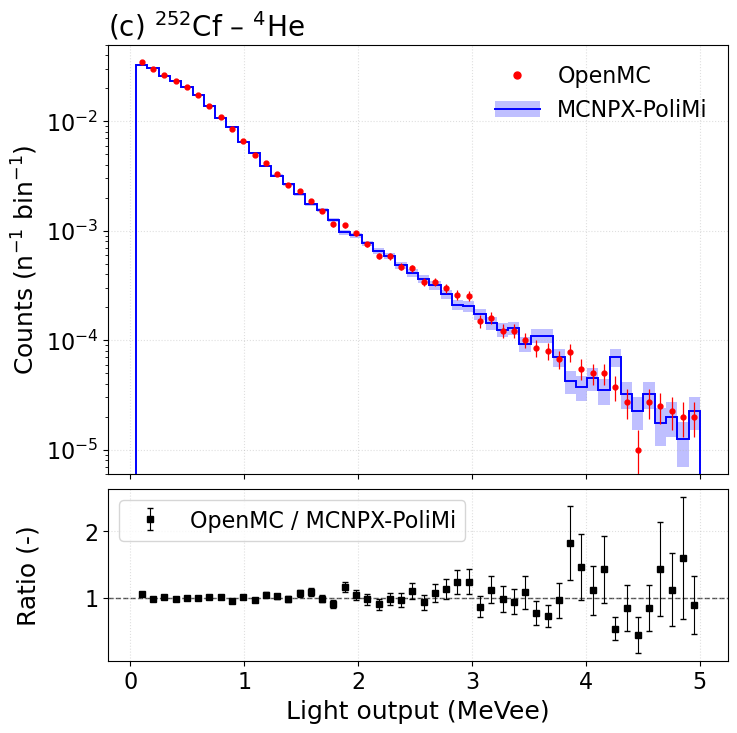

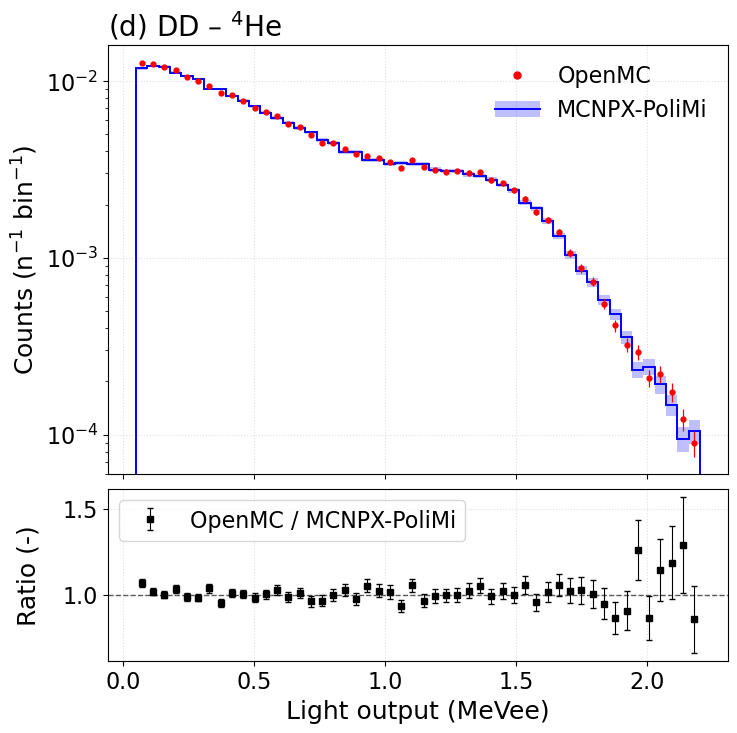


==================== PHOTON ====================


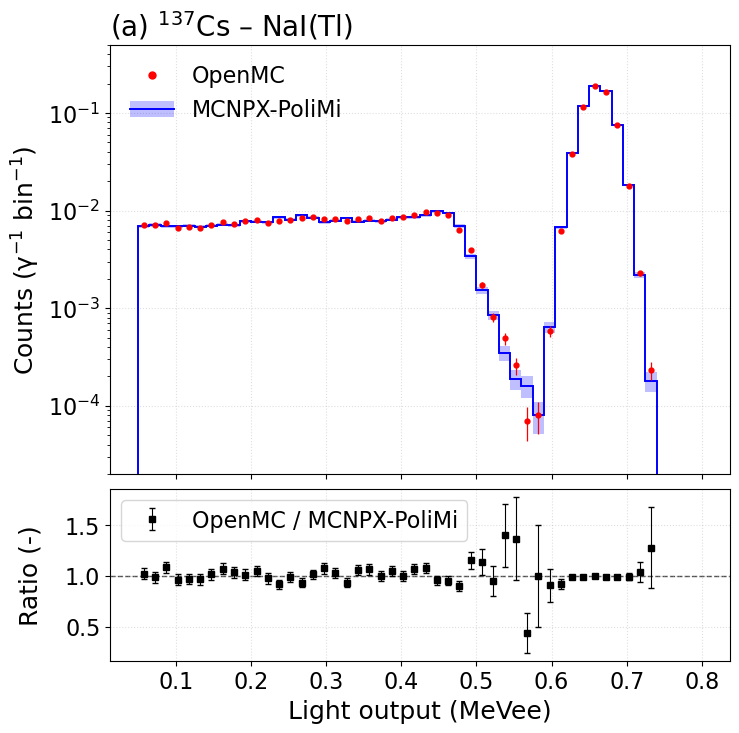

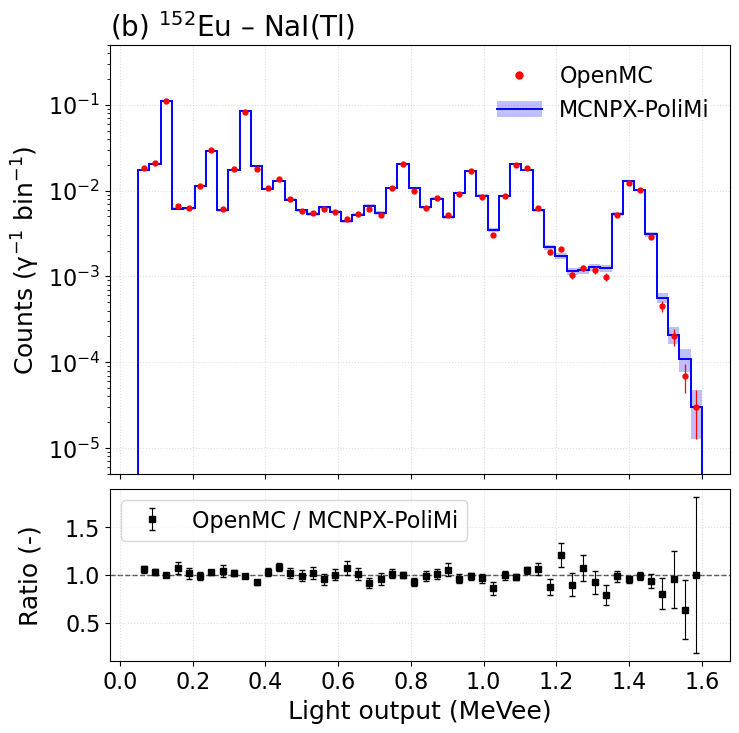

In [4]:
summary = {}

for particle in PARTICLES:
    print(f"\n==================== {particle.upper()} ====================")
    cases = [case for case in CASES if case["particle"] == particle]

    for k, case in enumerate(cases):
        folder = os.path.join(RESULTS_DIR, case["folder"])
        test = load_histogram(os.path.join(folder, CODES[TEST_CODE]["file"].format(particle=particle)),
                              CODES[TEST_CODE]["label"])
        ref  = load_histogram(os.path.join(folder, CODES[REFERENCE]["file"].format(particle=particle)),
                              CODES[REFERENCE]["label"])
        check_compatible(test, ref, case["folder"])

        pull, stats = compute_pull(test, ref)
        summary[(particle, case["folder"])] = stats
        
        fig = plot_comparison_ratio(test, ref, case,
                                    par=PAR_SYMBOL[particle],
                                    style=PLOT_STYLE,
                                    panel_label=f"({chr(ord('a') + k)}) {case['label']}", ylim=case.get("ylim"))

        # fig = plot_comparison_ratio(test, ref, pull, stats, case,
        #                       par=PAR_SYMBOL[particle],
        #                       style=PLOT_STYLE,
        #                       panel_label=f"({chr(ord('a') + k)}) {case['label']}",
        #                       ylim=YLIM,
        #                       low_counts=LOW_COUNTS)        

        if SAVE_FIG:
            os.makedirs(FIG_DIR, exist_ok=True)
            name = (f"{TEST_CODE}_vs_{REFERENCE}_LO_"
                    f"{case['folder'].replace('/', '_')}_{particle}.{FIG_FMT}")
            fig.savefig(os.path.join(FIG_DIR, name), dpi=300, bbox_inches="tight")
        plt.show()

# Summary

Expected values for two codes that agree within statistics: χ²/ndf ≈ 1, mean pull ≈ 0, std pull ≈ 1,
≈ 68 % of the bins within 1σ and ≈ 95 % within 2σ.

In [5]:
summary_df = pd.DataFrame(summary).T
summary_df.index.names = ["particle", "case"]
summary_df["bins used"] = summary_df["bins used"].astype(int)
summary_df.round(2)

bins used  chi2/ndf  mean pull  std pull  \
particle case                                                             
neutron  trans-stilbene/252Cf         49      1.34       0.10      1.17   
         trans-stilbene/DD            50      2.09      -0.03      1.46   
         helium4/252Cf                50      1.41       0.20      1.18   
         helium4/DD                   50      1.02       0.15      1.01   
photon   sodium-iodide/137Cs          46      1.08       0.04      1.05   
         sodium-iodide/152Eu          49      1.03      -0.13      1.02   

                               within 1σ [%]  within 2σ [%]  
particle case                                                
neutron  trans-stilbene/252Cf          67.35          95.92  
         trans-stilbene/DD             62.00          84.00  
         helium4/252Cf                 60.00          94.00  
         helium4/DD                    72.00          96.00  
photon   sodium-iodide/137Cs           56.52         100.00  
         sodium-iodide/152Eu           67.35          97.96

# Energy resolution models used in pyMPPost

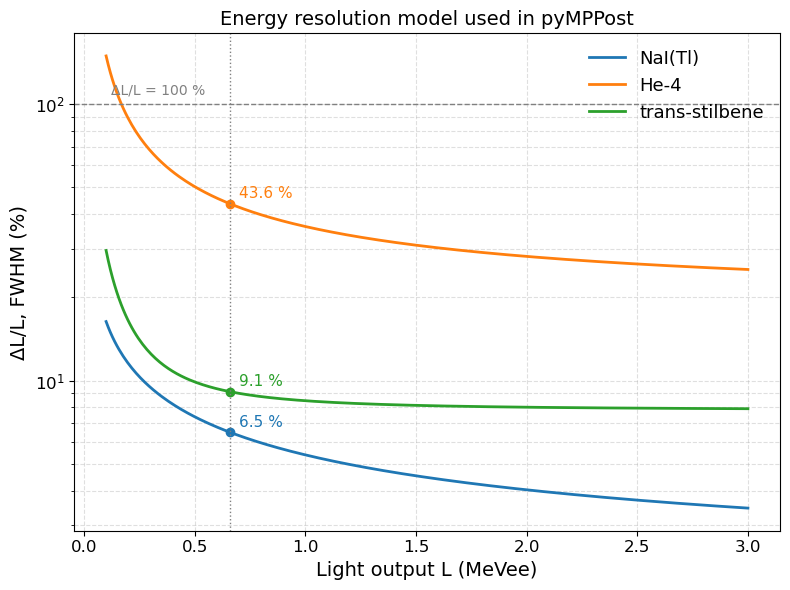

In [6]:
# pyMPPost resolution parameters [delta1, delta2 (MeVee^0.5), delta3 (MeVee)]
RESOLUTION = {
    "NaI(Tl)":        [0.0186, 0.0505, 0.003],
    "He-4":           [0.187,  0.2855, 0.1175],
    "trans-stilbene": [0.078,  0.017,  0.028],
}
L_REF = 0.661657                      # Cs-137 photopeak [MeVee]


def rel_resolution(L, d1, d2, d3):
    """Relative FWHM resolution dL/L = sqrt(d1^2 + d2^2/L + d3^2/L^2), L in MeVee."""
    return np.sqrt(d1**2 + d2**2 / L + d3**2 / L**2)


L = np.linspace(0.1, 3.0, 300)        # light output [MeVee]

fig, ax = plt.subplots(figsize=(8, 6))
for name, (d1, d2, d3) in RESOLUTION.items():
    line, = ax.plot(L, 100 * rel_resolution(L, d1, d2, d3), lw=2, label=name)
    r_ref = 100 * rel_resolution(L_REF, d1, d2, d3)
    ax.plot(L_REF, r_ref, "o", color=line.get_color())
    ax.annotate(f"{r_ref:.1f} %", (L_REF, r_ref), textcoords="offset points",
                xytext=(6, 4), color=line.get_color(), fontsize=11)

ax.axvline(L_REF, color="gray", ls=":", lw=1)
ax.axhline(100, color="gray", ls="--", lw=1)        # FWHM equal to the light output itself
ax.text(L[0] + 0.02, 108, "ΔL/L = 100 %", color="gray", fontsize=10)

ax.set_yscale("log")
ax.set_xlabel("Light output L (MeVee)", fontsize=14)
ax.set_ylabel("ΔL/L, FWHM (%)", fontsize=14)
ax.set_title("Energy resolution model used in pyMPPost", fontsize=14)
ax.grid(True, which="both", ls="--", alpha=0.4)
ax.tick_params(labelsize=12)
ax.legend(fontsize=13, frameon=False)
plt.tight_layout()
plt.show()

In [7]:
RESULTS_DIR = "/Users/loren/WORKSPACE/PHOTON/verification-and-validation/3-coupling-OpenMC-MPPost/results/"

CASES = [  # (detector folder, source folder, particle, label for the table)
    ("trans-stilbene", "252Cf", "neutron", r"Stilbene, $^{252}$Cf"),
    ("trans-stilbene", "DD",    "neutron", r"Stilbene, DD"),
    ("helium4",        "252Cf", "neutron", r"$^{4}$He, $^{252}$Cf"),
    ("helium4",        "DD",    "neutron", r"$^{4}$He, DD"),
    ("sodium-iodide",  "137Cs", "photon",  r"NaI(Tl), $^{137}$Cs"),
    ("sodium-iodide",  "152Eu", "photon",  r"NaI(Tl), $^{152}$Eu"),
]

def load_total(path, code):
    """Total pulses per source particle in the histogram range and its 1-sigma uncertainty."""
    h = joblib.load(path)
    y = np.asarray(h[f"{code}-counts-norm"])
    err = np.asarray(h[f"{code}-counts-err-norm"])
    return y.sum(), np.sqrt(np.sum(err**2))   # independent Poisson bins

rows = []
for det, src, particle, label in CASES:
    case_dir = os.path.join(RESULTS_DIR, det, src)
    o, eo = load_total(os.path.join(case_dir, f"OpenMC_LO_histogram_{particle}.joblib"), "OpenMC")
    m, em = load_total(os.path.join(case_dir, f"MCNPX-PoliMi_LO_histogram_{particle}.joblib"), "MCNPX-PoliMi")
    r = o / m
    er = r * np.sqrt((eo / o)**2 + (em / m)**2)
    rows.append({"detector": det, "source": src, "OpenMC": o, "OpenMC err": eo,
                 "MCNPX-PoliMi": m, "MCNPX-PoliMi err": em,
                 "ratio": r, "ratio err": er, "deviation [sigma]": (r - 1) / er,
                 "label": label})

df = pd.DataFrame(rows)
display(df.drop(columns="label").round(4))

# Rows ready to paste into tab:integral
for _, row in df.iterrows():
    print(f"{row['label']} & "
          f"${row['OpenMC']:.4f} \\pm {row['OpenMC err']:.4f}$ & "
          f"${row['MCNPX-PoliMi']:.4f} \\pm {row['MCNPX-PoliMi err']:.4f}$ & "
          f"${row['ratio']:.3f} \\pm {row['ratio err']:.3f}$ \\\\")

,detector,source,OpenMC,OpenMC err,MCNPX-PoliMi,MCNPX-PoliMi err,ratio,ratio err,deviation [sigma]
0,trans-stilbene,252Cf,0.3696,0.0010,0.3700,0.0010,0.9991,0.0037,-0.2502
1,trans-stilbene,DD,0.4042,0.0010,0.4061,0.0010,0.9951,0.0035,-1.3946
2,helium4,252Cf,0.2211,0.0007,0.2193,0.0007,1.0084,0.0048,1.7511
3,helium4,DD,0.2122,0.0007,0.2109,0.0007,1.0061,0.0049,1.2456
4,sodium-iodide,137Cs,0.8467,0.0029,0.8499,0.0029,0.9962,0.0048,-0.7832
5,sodium-iodide,152Eu,0.5970,0.0024,0.5984,0.0024,0.9976,0.0058,-0.4141


Stilbene, $^{252}$Cf & $0.3696 \pm 0.0010$ & $0.3700 \pm 0.0010$ & $0.999 \pm 0.004$ \\
Stilbene, DD & $0.4042 \pm 0.0010$ & $0.4061 \pm 0.0010$ & $0.995 \pm 0.003$ \\
$^{4}$He, $^{252}$Cf & $0.2211 \pm 0.0007$ & $0.2193 \pm 0.0007$ & $1.008 \pm 0.005$ \\
$^{4}$He, DD & $0.2122 \pm 0.0007$ & $0.2109 \pm 0.0007$ & $1.006 \pm 0.005$ \\
NaI(Tl), $^{137}$Cs & $0.8467 \pm 0.0029$ & $0.8499 \pm 0.0029$ & $0.996 \pm 0.005$ \\
NaI(Tl), $^{152}$Eu & $0.5970 \pm 0.0024$ & $0.5985 \pm 0.0024$ & $0.998 \pm 0.006$ \\
